In [1]:
from pathlib import Path
import zipfile
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 2026
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data")
if not (DATA_DIR / "mnist_train.csv").exists():
    archive = Path("data.zip")
    if archive.exists():
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(".")
if not (DATA_DIR / "mnist_train.csv").exists():
    raise FileNotFoundError("Нужна папка data/ с mnist_train.csv и mnist_test.csv или архив data.zip рядом с ноутбуком.")

class MNISTCSV(Dataset):
    def __init__(self, path):
        arr = np.loadtxt(path, delimiter=",", dtype=np.uint8)
        self.labels = torch.from_numpy(arr[:, 0].astype(np.int64))
        self.images = torch.from_numpy(arr[:, 1:].copy()).float().div_(255).reshape(-1, 1, 28, 28)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.images[i], self.labels[i]

train_ds = MNISTCSV(DATA_DIR / "mnist_train.csv")
test_ds = MNISTCSV(DATA_DIR / "mnist_test.csv")
print(f"Train: {len(train_ds):,}; test: {len(test_ds):,}; device: {device}")


Train: 60,000; test: 10,000; device: cpu


In [4]:
class DenseMNIST(nn.Module):
    def __init__(self, z_size=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(), nn.Linear(784, z_size), nn.ReLU(), nn.Dropout(0.15),
            nn.Linear(z_size, z_size // 2), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(z_size // 2, 10)
        )
    def forward(self, x): return self.net(x)

def run_experiment(model, epochs=8, batch_size=128, lr=0.001):
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, num_workers=0)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "test_accuracy": []}
    for epoch in range(epochs):
        model.train(); total_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward(); optimizer.step()
            total_loss += loss.item() * len(y)
        model.eval(); correct = count = 0
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                correct += (model(x).argmax(1) == y).sum().item(); count += len(y)
        history["train_loss"].append(total_loss / len(train_ds))
        history["test_accuracy"].append(correct / count)
        print(f"Epoch {epoch+1}/{epochs}: train loss={history['train_loss'][-1]:.4f}, test accuracy={correct/count:.4%}")
    return model, history

dense_model, dense_history = run_experiment(DenseMNIST(256), epochs=8, batch_size=128, lr=0.001)


Epoch 1/8: train loss=0.3664, test accuracy=95.1800%
Epoch 2/8: train loss=0.1469, test accuracy=96.6600%
Epoch 3/8: train loss=0.1026, test accuracy=97.3900%
Epoch 4/8: train loss=0.0839, test accuracy=97.5700%
Epoch 5/8: train loss=0.0679, test accuracy=97.6200%
Epoch 6/8: train loss=0.0582, test accuracy=97.8600%
Epoch 7/8: train loss=0.0526, test accuracy=98.0600%
Epoch 8/8: train loss=0.0462, test accuracy=98.1800%


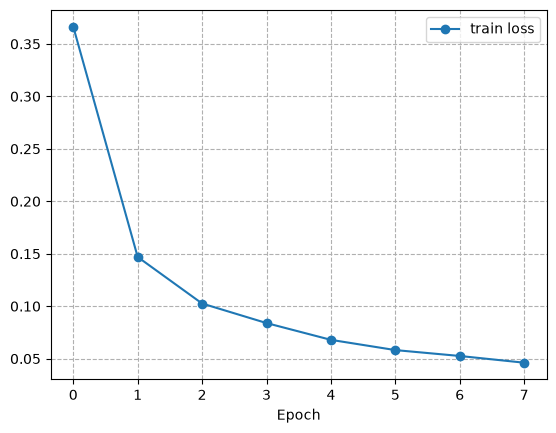

Полносвязная сеть: итоговая точность 98.1800%


In [5]:
plt.plot(dense_history["train_loss"], marker="o", label="train loss")
plt.xlabel("Epoch"); plt.grid(True, linestyle="--"); plt.legend(); plt.show()
print(f"Полносвязная сеть: итоговая точность {dense_history['test_accuracy'][-1]:.4%}")


In [ ]:
class ConvMNIST(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout2d(0.10),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout2d(0.15)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.25), nn.Linear(128, 10)
        )
    def forward(self, x): return self.classifier(self.features(x))

cnn_model, cnn_history = run_experiment(ConvMNIST(), epochs=8, batch_size=128, lr=0.001)


Epoch 1/8: train loss=0.1619, test accuracy=98.3600%
Epoch 2/8: train loss=0.0556, test accuracy=99.1800%
Epoch 3/8: train loss=0.0401, test accuracy=99.2400%
Epoch 4/8: train loss=0.0340, test accuracy=99.2200%


In [ ]:
plt.plot(cnn_history["test_accuracy"], marker="o", label="CNN test accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.grid(True, linestyle="--"); 
plt.legend(); 
plt.show()
print(f"CNN: итоговая точность {cnn_history['test_accuracy'][-1]:.4%}")
